# Khảo sát chuyển rủi ro sang phương án đăng ký

Phân tích **EXPLORATORY, chưa phải mô hình cuối**. Dữ liệu học vụ gắn nhãn **REAL (UCI-697)**; hồ sơ, học phần, hệ số độ khó và kế hoạch gắn nhãn **SIMULATED** hoặc **GIẢ ĐỊNH kịch bản**. Mốc dự báo T1 chỉ dùng thuộc tính `available_at` là `T0` hoặc `T1_known`. `T1_decision` chỉ được dùng ở phép thử chẩn đoán M1 và phân tích tải C.3; tuyệt đối không dùng trong feature cơ sở.

Chạy từ thư mục gốc dự án, sau khi cài dependencies hiện có của notebook 01. Seed cố định: `20261105`.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))

from src.analysis.risk_to_plan_exploration import run_exploration

result = run_exploration()
print(f"Data label: {result['data_label']}; seed={result['seed']}")
print(f"T1 base features: {result['feature_count']}")
feature_gate_passed = all(
    name not in {
        "Debtor", "Tuition fees up to date", "Scholarship holder",
        "Unemployment rate", "Inflation rate", "GDP",
        "Curricular units 2nd sem (credited)",
        "Curricular units 2nd sem (enrolled)",
        "Curricular units 2nd sem (evaluations)",
        "Curricular units 2nd sem (approved)",
        "Curricular units 2nd sem (grade)",
        "Curricular units 2nd sem (without evaluations)",
        "Target",
    }
    for name in result["features"]
)
assert feature_gate_passed
print("Feature timestamp gate passed:", feature_gate_passed)

Data label: REAL (UCI-697); seed=20261105
T1 base features: 24
Feature timestamp gate passed: True


## C.1 — P(Dropout) mức sinh viên tại T1

,data_label,CV accuracy mean,CV macro-F1 mean,CV F1 Dropout mean,holdout precision Dropout,holdout recall Dropout,holdout F1 Dropout,holdout Brier (one-vs-rest)
0,"REAL (UCI-697), exploratory",0.714,0.6164,0.7093,0.701,0.7183,0.7096,0.1211


,Dropout,Enrolled,Graduate
Actual \ Predicted,,,
Dropout,204,20,60
Enrolled,48,46,65
Graduate,39,24,379


Risk tier thresholds selected from training OOF validation:
{'low_max_p_dropout': 0.029362255379757403, 'medium_max_p_dropout': 0.1386536269981684, 'medium_recall_target': 0.98, 'high_recall_target': 0.9, 'validation_method': '5-fold stratified OOF on training split', 'validation_recall_medium': 0.980650835532102, 'validation_recall_high': 0.9006156552330695, 'oof_warning_distribution':          tier                 data_label  students  dropout_count  \
0         Cao  REAL (UCI-697), train OOF      1923         1024.0   
1  Trung bình  REAL (UCI-697), train OOF      1166           91.0   
2        Thấp  REAL (UCI-697), train OOF       450           22.0   

   observed_dropout_rate  student_share       ppv  
0               0.532501       0.543374  0.532501  
1               0.078045       0.329472  0.078045  
2               0.048889       0.127155  0.048889  , 'calibrated_restriction_threshold': 0.5, 'restriction_minimum_ppv': 0.7, 'restriction_threshold_sensitivity':               

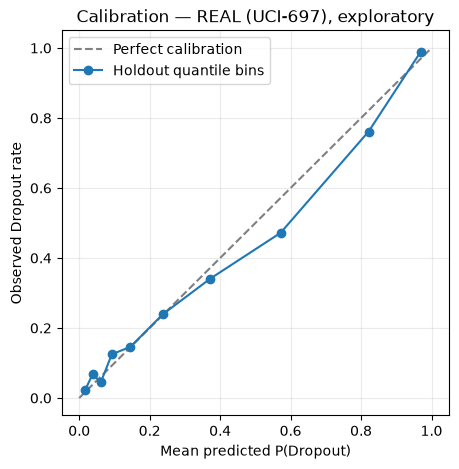

In [2]:
dropout = result["dropout_model"]
display(pd.DataFrame([{
    "data_label": "REAL (UCI-697), exploratory",
    "CV accuracy mean": dropout["cv_accuracy_mean"],
    "CV macro-F1 mean": dropout["cv_f1_macro_mean"],
    "CV F1 Dropout mean": dropout["cv_f1_dropout_mean"],
    "holdout precision Dropout": dropout["holdout_precision_dropout"],
    "holdout recall Dropout": dropout["holdout_recall_dropout"],
    "holdout F1 Dropout": dropout["holdout_f1_dropout"],
    "holdout Brier (one-vs-rest)": dropout["brier_dropout"],
}]).round(4))

display(pd.DataFrame(
    dropout["confusion_matrix"],
    index=dropout["confusion_labels"],
    columns=dropout["confusion_labels"],
).rename_axis("Actual \\ Predicted"))
print("Risk tier thresholds selected from training OOF validation:")
print(dropout["risk_tier_validation_thresholds"])

calibration = dropout["calibration"]
plt.figure(figsize=(5, 5))
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Perfect calibration")
plt.plot(
    calibration["predicted_mean"],
    calibration["observed_dropout_rate"],
    marker="o",
    label="Holdout quantile bins",
)
plt.xlabel("Mean predicted P(Dropout)")
plt.ylabel("Observed Dropout rate")
plt.title("Calibration — REAL (UCI-697), exploratory")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## C.2 — Tỷ lệ đạt học phần HK2

`pass_rate_2 = approved_2nd / enrolled_2nd`, chỉ định nghĩa khi số học phần HK2 đăng ký lớn hơn 0. Có 180 sinh viên không đăng ký HK2 nên không có mẫu số, bị loại khỏi nhãn hồi quy. `without evaluations` vẫn nằm trong mẫu số `enrolled`; các unit đó chưa được tính là đạt, và được thống kê riêng để thể hiện bất định về cơ hội đánh giá. Đặc trưng mô hình vẫn chỉ là T0 + T1-known.


In [3]:
pass_rate = result["pass_rate_model"]
display(pd.DataFrame([{
    "data_label": "REAL (UCI-697), exploratory",
    "students with enrolled_2 > 0": pass_rate["eligible_students"],
    "students excluded (enrolled_2 = 0)": pass_rate["excluded_zero_enrollment"],
    "CV MAE": pass_rate["cv_mae_mean"],
    "CV RMSE": pass_rate["cv_rmse_mean"],
    "holdout MAE": pass_rate["holdout_mae"],
    "holdout RMSE": pass_rate["holdout_rmse"],
    "holdout calibration decile MAE (raw)": pass_rate["holdout_calibration_mae_raw"],
    "holdout calibration decile MAE (isotonic)": pass_rate["holdout_calibration_mae_isotonic"],
    "holdout MAE (isotonic)": pass_rate["holdout_mae_isotonic"],
    "holdout RMSE (isotonic)": pass_rate["holdout_rmse_isotonic"],
    "HK2 units without evaluations": result["without_evaluation_units_hk2"],
}]).round(4))

,data_label,students with enrolled_2 > 0,students excluded (enrolled_2 = 0),CV MAE,CV RMSE,holdout MAE,holdout RMSE,holdout calibration decile MAE (raw),holdout calibration decile MAE (isotonic),holdout MAE (isotonic),holdout RMSE (isotonic),HK2 units without evaluations
0,"REAL (UCI-697), exploratory",4244,180,0.1201,0.184,0.124,0.1936,0.0125,0.0153,0.1244,0.1958,665


In [4]:
display(pass_rate["calibration_deciles_raw"].round(4))
display(pass_rate["calibration_deciles_isotonic"].round(4))
zero_enrollment = result["stratified_load"]["table"].query("hk2_enrolled_band == '0'")
print("Dropout rate among enrolled_2=0 (REAL):",
      zero_enrollment["dropout_rate"].iloc[0])

,decile,data_label,student_count,mean_predicted,mean_observed
0,0,"REAL (UCI-697), holdout calibration",85,0.0098,0.0124
1,1,"REAL (UCI-697), holdout calibration",85,0.2083,0.2375
2,2,"REAL (UCI-697), holdout calibration",85,0.5184,0.5310
3,3,"REAL (UCI-697), holdout calibration",85,0.7092,0.6737
4,4,"REAL (UCI-697), holdout calibration",85,0.7921,0.7884
5,5,"REAL (UCI-697), holdout calibration",84,0.8440,0.8531
6,6,"REAL (UCI-697), holdout calibration",85,0.8768,0.8773
7,7,"REAL (UCI-697), holdout calibration",85,0.9174,0.9124
8,8,"REAL (UCI-697), holdout calibration",85,0.9544,0.9440
9,9,"REAL (UCI-697), holdout calibration",85,0.9826,0.9664


,decile,data_label,student_count,mean_predicted,mean_observed
0,0,"REAL (UCI-697), holdout calibration",85,0.0081,0.0124
1,1,"REAL (UCI-697), holdout calibration",85,0.2070,0.2359
2,2,"REAL (UCI-697), holdout calibration",85,0.5158,0.5279
3,3,"REAL (UCI-697), holdout calibration",85,0.7221,0.6934
4,4,"REAL (UCI-697), holdout calibration",85,0.7816,0.7961
5,5,"REAL (UCI-697), holdout calibration",84,0.8349,0.8339
6,6,"REAL (UCI-697), holdout calibration",85,0.8797,0.8714
7,7,"REAL (UCI-697), holdout calibration",85,0.9255,0.9166
8,8,"REAL (UCI-697), holdout calibration",85,0.9669,0.9396
9,9,"REAL (UCI-697), holdout calibration",85,0.9872,0.9687


Dropout rate among enrolled_2=0 (REAL): 0.42777777777777776


## C.3 — Tải đăng ký và kết quả quan sát

Tầng năng lực HK1 chia theo quantile của tỷ lệ `approved_1st / enrolled_1st`; tải HK2 chia thành `0`, `1–5`, `6–7`, `8+` curricular units. Pass rate là pooled approved/enrolled theo tầng; Dropout rate là tỷ lệ sinh viên trong tầng. Đây là quan sát REAL, không phải hiệu ứng nhân quả.


In [5]:
load_table = result["stratified_load"]["table"].copy()
display(load_table.sort_values(
    ["hk1_ability", "hk2_enrolled_band"],
    key=lambda col: col.map({
        "Thấp": 0, "Trung bình": 1, "Cao": 2,
        "0": 0, "1-5": 1, "6-7": 2, "8+": 3,
    }) if col.name in {"hk1_ability", "hk2_enrolled_band"} else col,
).round(4))
print("Adjusted observational OR per extra HK2 unit:",
      round(result["stratified_load"]["adjusted_or_per_hk2_unit"], 6))
print("REAL HK2 denominator totals:")
display(result["stratified_load"]["overall"].round(4))
print("M3-prime baseline pooled by HK1 ability, REAL (UCI-697):")
display(result["stratified_load"]["m3_prime_table"].round(4))

display(load_table.pivot(
    index="hk1_ability", columns="hk2_enrolled_band", values="pass_rate_2"
).reindex(index=["Thấp", "Trung bình", "Cao"], columns=["0", "1-5", "6-7", "8+"]).round(3))

,data_label,hk1_ability,hk2_enrolled_band,student_count,students_with_hk2_enrollment,hk2_enrolled_units,hk2_approved_units,hk2_without_evaluations_units,pass_rate_2,dropout_rate
0,REAL (UCI-697),Thấp,0,180,0,0,0,0,NaN,0.4278
6,REAL (UCI-697),Thấp,1-5,578,578,2856,818,187,0.2864,0.6972
2,REAL (UCI-697),Thấp,6-7,495,495,3056,582,82,0.1904,0.8283
9,REAL (UCI-697),Thấp,8+,96,96,864,283,109,0.3275,0.7292
8,REAL (UCI-697),Trung bình,1-5,197,197,982,742,70,0.7556,0.2132
3,REAL (UCI-697),Trung bình,6-7,720,720,4490,3276,29,0.7296,0.2750
7,REAL (UCI-697),Trung bình,8+,430,430,3957,3331,65,0.8418,0.1628
4,REAL (UCI-697),Cao,1-5,307,307,1522,1393,69,0.9152,0.1075
1,REAL (UCI-697),Cao,6-7,1002,1002,6060,5542,17,0.9145,0.0928
5,REAL (UCI-697),Cao,8+,419,419,3784,3657,37,0.9664,0.0597


Adjusted observational OR per extra HK2 unit: 1.000469
REAL HK2 denominator totals:


,data_label,students,students_with_hk2_enrollment,students_zero_hk2_enrollment,hk2_pass_rate_pooled,dropout_rate,adjusted_dropout_odds_ratio_per_extra_hk2_unit
0,REAL (UCI-697),4424,4244,180,0.7118,0.3212,1.0005


M3-prime baseline pooled by HK1 ability, REAL (UCI-697):


,data_label,hk1_ability,student_count_with_hk2_enrollment,hk2_enrolled_units,hk2_approved_units,m3_prime_pass_rate
0,REAL (UCI-697),Thấp,1169,6776,1683,0.2484
1,REAL (UCI-697),Cao,1728,11366,10592,0.9319
2,REAL (UCI-697),Trung bình,1347,9429,7349,0.7794


hk2_enrolled_band,0,1-5,6-7,8+
hk1_ability,,,,
Thấp,NaN,0.286,0.190,0.328
Trung bình,NaN,0.756,0.730,0.842
Cao,NaN,0.915,0.915,0.966


## M1 — Diagnostic counterfactual, loại làm phương pháp chính

M1 thêm biến quyết định `enrolled_2` vào mô hình Dropout rồi thay đổi giá trị cho một vector đặc trưng đại diện. Đây không phải mô hình vận hành hợp lệ tại T1, và không phải can thiệp nhân quả.


In [6]:
m1 = result["m1"]
display(m1["counterfactual_table"].round(4))
assert m1["counterfactual_table"]["predicted_p_dropout"].diff().dropna().gt(0).all()
print("Holdout Brier with T1_decision:",
      round(m1["holdout_brier_with_t1_decision"], 6))
print("Holdout Brier without T1_decision:",
      round(m1["holdout_brier_without_t1_decision"], 6))
print("Binary same-controls OR per unit:",
      round(m1["binary_same_controls_or_per_enrolled_unit"], 6))
print("Three-class effective counterfactual OR per unit:",
      round(m1["multiclass_effective_counterfactual_or_per_enrolled_unit"], 6))

,data_label,counterfactual_hk2_enrolled,predicted_p_dropout
0,"REAL (UCI-697), diagnostic M1",1,0.0570
1,"REAL (UCI-697), diagnostic M1",3,0.0767
2,"REAL (UCI-697), diagnostic M1",5,0.1017
3,"REAL (UCI-697), diagnostic M1",6,0.1164
4,"REAL (UCI-697), diagnostic M1",8,0.1507
5,"REAL (UCI-697), diagnostic M1",10,0.1914
6,"REAL (UCI-697), diagnostic M1",12,0.2381


Holdout Brier with T1_decision: 0.121387
Holdout Brier without T1_decision: 0.121147
Binary same-controls OR per unit: 1.314506
Three-class effective counterfactual OR per unit: 1.161026


## M2/M3' — Hệ số môn học SIMULATED và so sánh persona

        M2 dùng `p_student_pass × f_difficulty × g_load × r_retake`, cắt về [0,1]. M3' lấy tỷ lệ REAL theo riêng tầng năng lực HK1, gộp mọi mức tải; tầng hiếm dưới cỡ mẫu tối thiểu trong config được gộp với tầng kề. Tỷ lệ theo band tải chỉ giữ làm minh chứng thiên lệch chọn lọc.


In [7]:
persona = result["persona"]
display(persona["difficulty_factors_table"].round(4))
display(persona["table"][[
    "data_label", "student_id", "persona", "ability_tier_from_real_hk1",
    "scenario_credit_budget", "planned_credits_actual", "selected_course_ids",
    "p_dropout_student_level", "p_student_pass_rate_model",
    "m2_expected_credits_passed", "m2_expected_failed_courses",
    "m3_prime_p_pass_by_ability", "m3_band_p_pass_selection_bias_reference",
    "m3_expected_failed_courses", "status",
]].round(4))

,data_label,group,median_grade_10,raw_relative_factor,difficulty_factor_clipped_q10_q90
0,SIMULATED,An toàn thông tin,7.10,1.0000,1.0000
1,SIMULATED,Cơ sở toán học,6.25,0.8803,0.8803
2,SIMULATED,Dữ liệu,7.80,1.0986,1.0986
3,SIMULATED,Hệ thống,6.75,0.9507,0.9507
4,SIMULATED,Hệ thống thông tin,8.30,1.1690,1.1690
5,SIMULATED,Kỹ nghệ phần mềm,7.50,1.0563,1.0563
6,SIMULATED,Lập trình,7.20,1.0141,1.0141
7,SIMULATED,Phát triển ứng dụng,7.60,1.0704,1.0704
8,SIMULATED,Quản lý,8.10,1.1408,1.1408
9,SIMULATED,Thực tập,7.80,1.0986,1.0986


,data_label,student_id,persona,ability_tier_from_real_hk1,scenario_credit_budget,planned_credits_actual,selected_course_ids,p_dropout_student_level,p_student_pass_rate_model,m2_expected_credits_passed,m2_expected_failed_courses,m3_prime_p_pass_by_ability,m3_band_p_pass_selection_bias_reference,m3_expected_failed_courses,status
0,SIMULATED,S001,"Giỏi, đúng tiến độ",Cao,12,12,"IT501, IT502, IT503, IT504",0.0244,0.9807,11.7390,0.0870,0.9319,0.9152,0.2724,Đạt ngân sách mô phỏng
1,SIMULATED,S001,"Giỏi, đúng tiến độ",Cao,15,14,"IT501, IT502, IT503, IT504, EL506",0.0244,0.9807,13.7390,0.0870,0.9319,0.9152,0.3405,Không đủ học phần đủ điều kiện để đạt ngân sách
2,SIMULATED,S001,"Giỏi, đúng tiến độ",Cao,18,18,"IT501, IT502, IT503, IT504, EL506, IT505, EL706",0.0244,0.9807,16.9597,0.3878,0.9319,0.9145,0.4767,Đạt ngân sách mô phỏng
3,SIMULATED,S002,"Trung bình, đúng tiến độ",Trung bình,12,12,"IT501, IT502, IT503, IT504",0.3372,0.5933,7.3082,1.5639,0.7794,0.7556,0.8824,Đạt ngân sách mô phỏng
4,SIMULATED,S002,"Trung bình, đúng tiến độ",Trung bình,15,14,"IT501, IT502, IT503, IT504, EL506",0.3372,0.5933,8.5951,1.9205,0.7794,0.7556,1.1030,Không đủ học phần đủ điều kiện để đạt ngân sách
5,SIMULATED,S002,"Trung bình, đúng tiến độ",Trung bình,18,18,"IT501, IT502, IT503, IT504, EL506, IT505, EL706",0.3372,0.5933,10.2613,2.9994,0.7794,0.7296,1.5442,Đạt ngân sách mô phỏng
6,SIMULATED,S003,"Yếu, chậm tiến độ",Thấp,12,12,"IT104, IT501, IT502, IT503",0.9926,0.0489,0.5914,3.8029,0.2484,0.2864,3.0065,Đạt ngân sách mô phỏng
7,SIMULATED,S003,"Yếu, chậm tiến độ",Thấp,15,15,"IT104, IT501, IT502, IT503, IT504",0.9926,0.0489,0.7383,4.7539,0.2484,0.1904,3.7581,Đạt ngân sách mô phỏng
8,SIMULATED,S003,"Yếu, chậm tiến độ",Thấp,18,17,"IT104, IT501, IT502, IT503, IT504, EL506",0.9926,0.0489,0.8133,5.7118,0.2484,0.1904,4.5097,Không đủ học phần đủ điều kiện để đạt ngân sách
9,SIMULATED,S004,Có nhiều môn nợ,Thấp,12,12,"IT104, IT302, IT503, IT504",0.9926,0.0489,0.5832,3.8056,0.2484,0.2864,3.0065,Đạt ngân sách mô phỏng


## C.6 — Kiểm tra logic và khả năng khả thi

In [8]:
scenario_results = persona["table"]
monotonic_checks = []
for student_id, group in scenario_results.groupby("student_id"):
    group = group.sort_values("scenario_credit_budget")
    monotonic_checks.append({
        "data_label": "SIMULATED",
        "student_id": student_id,
        "M2_expected_failures_non_decreasing": bool(
            group["m2_expected_failed_courses"].diff().dropna().ge(-1e-9).all()
        ),
        "M3prime_expected_failures_non_decreasing": bool(
            group["m3_expected_failed_courses"].diff().dropna().ge(-1e-9).all()
        ),
        "credits_increase_or_saturate": bool(
            group["m2_expected_credits_passed"].diff().dropna().ge(-1e-9).all()
        ),
        "budgets_underfilled": bool(
            (group["planned_credits_actual"] < group["scenario_credit_budget"]).any()
        ),
    })
checks = pd.DataFrame(monotonic_checks)
display(checks)
assert checks["M2_expected_failures_non_decreasing"].all()
assert checks["M3prime_expected_failures_non_decreasing"].all()
assert checks["credits_increase_or_saturate"].all()
assert scenario_results.loc[
    scenario_results["student_id"].eq("S001"), "p_student_pass_rate_model"
].iloc[0] > scenario_results.loc[
    scenario_results["student_id"].eq("S003"), "p_student_pass_rate_model"
].iloc[0]
display(scenario_results.groupby(
    ["student_id", "persona"], as_index=False
).agg(
    p_student_pass_rate_model=("p_student_pass_rate_model", "first"),
    p_dropout_student_level=("p_dropout_student_level", "first"),
).sort_values("p_student_pass_rate_model", ascending=False).round(4))

,data_label,student_id,M2_expected_failures_non_decreasing,M3prime_expected_failures_non_decreasing,credits_increase_or_saturate,budgets_underfilled
0,SIMULATED,S001,True,True,True,True
1,SIMULATED,S002,True,True,True,True
2,SIMULATED,S003,True,True,True,True
3,SIMULATED,S004,True,True,True,True
4,SIMULATED,S005,True,True,True,True
5,SIMULATED,S006,True,True,True,True
6,SIMULATED,S007,True,True,True,True
7,SIMULATED,S008,True,True,True,True


,student_id,persona,p_student_pass_rate_model,p_dropout_student_level
0,S001,"Giỏi, đúng tiến độ",0.9807,0.0244
7,S008,"Giỏi, tích lũy gần hoàn tất",0.9807,0.0244
4,S005,Nợ môn chặn chuỗi tiên quyết,0.5933,0.3372
1,S002,"Trung bình, đúng tiến độ",0.5933,0.3372
5,S006,"Gần tốt nghiệp, còn một môn nợ",0.5933,0.3372
2,S003,"Yếu, chậm tiến độ",0.0489,0.9926
6,S007,Nguy cơ chậm do trượt môn nền tảng,0.0489,0.9926
3,S004,Có nhiều môn nợ,0.0489,0.9926


## C.7 — Độ nhạy của tải, độ khó và học lại

Các hệ số dưới đây là **GIẢ ĐỊNH kịch bản**, không phải ước lượng nhân quả. Độ nhạy tải tại ngân sách 12/15/18 dùng pooled pass rate REAL làm mốc minh họa, `f_difficulty = 1`, `r_retake = 1`; nó không đại diện cho dự báo cá nhân. Bảng persona thay đổi đồng thời các hệ số trong lưới config.


In [9]:
display(persona["load_sensitivity"].round(4))
display(persona["sensitivity_summary"].round(4))
print("Sensitivity grid from config:", result["exploration_config"])

,data_label,credit_budget,simulated_average_credits_per_unit,equivalent_curricular_units,nearest_integer_units_for_band,real_median_hk2_units,lambda_assumption,g_load,reference_p_pass_real_pooled,scenario_p_pass_one_course
0,REAL baseline + GIẢ ĐỊNH kịch bản,12,2.6667,4.500,5,6.0,0.0,1.0000,0.7118,0.7118
1,REAL baseline + GIẢ ĐỊNH kịch bản,12,2.6667,4.500,5,6.0,0.1,1.0000,0.7118,0.7118
2,REAL baseline + GIẢ ĐỊNH kịch bản,12,2.6667,4.500,5,6.0,0.3,1.0000,0.7118,0.7118
3,REAL baseline + GIẢ ĐỊNH kịch bản,15,2.6667,5.625,6,6.0,0.0,1.0000,0.7118,0.7118
4,REAL baseline + GIẢ ĐỊNH kịch bản,15,2.6667,5.625,6,6.0,0.1,1.0000,0.7118,0.7118
5,REAL baseline + GIẢ ĐỊNH kịch bản,15,2.6667,5.625,6,6.0,0.3,1.0000,0.7118,0.7118
6,REAL baseline + GIẢ ĐỊNH kịch bản,18,2.6667,6.750,7,6.0,0.0,1.0000,0.7118,0.7118
7,REAL baseline + GIẢ ĐỊNH kịch bản,18,2.6667,6.750,7,6.0,0.1,0.9277,0.7118,0.6603
8,REAL baseline + GIẢ ĐỊNH kịch bản,18,2.6667,6.750,7,6.0,0.3,0.7985,0.7118,0.5684


,student_id,scenario_credit_budget,planned_credits_actual,expected_failed_min,expected_failed_max,expected_credits_min,expected_credits_max,risk_index_min,risk_index_max
0,S001,12,12,0.0000,0.7790,9.6631,12.0000,0.0000,19.4742
1,S001,15,14,0.0000,0.9281,11.3648,14.0000,0.0000,18.8230
2,S001,18,18,0.0000,2.4471,11.6779,18.0000,0.0000,35.1228
3,S002,12,12,1.0767,2.0512,5.8465,8.7698,26.9183,51.2789
4,S002,15,14,1.3045,2.5364,6.8761,10.3142,26.3274,50.8849
5,S002,18,18,1.8254,4.2453,7.0656,13.2725,26.2637,60.7469
6,S003,12,12,3.7580,3.8459,0.4623,0.7260,93.9502,96.1474
7,S003,15,15,4.6993,4.8067,0.5798,0.9022,93.9856,96.1349
8,S003,18,17,5.6356,5.7894,0.5940,1.0295,93.9439,96.5061
9,S004,12,12,3.7549,3.8524,0.4428,0.7354,93.8717,96.3101


Sensitivity grid from config: {'base_load_lambda': 0.1, 'load_lambdas': [0.0, 0.1, 0.3], 'difficulty_multipliers': [0.8, 1.0, 1.2], 'retake_multipliers': [0.9, 1.0, 1.1], 'scenario_credits': [12, 15, 18], 'm3_minimum_students': 30, 'restriction_minimum_ppv': 0.7, 'restriction_minimum_count': 30, 'restriction_minimum_probability': 0.5, 'restriction_probability_grid': [0.5, 0.55, 0.6, 0.65, 0.7, 0.75]}
